<a href="https://colab.research.google.com/github/caroheymes/-Jedha-Uber-pickups-unsupervised-machine-learning-/blob/master/final_Jedha_uber_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/58/Uber_logo_2018.svg/1024px-Uber_logo_2018.svg.png" alt="UBER LOGO" width="50%" />

# UBER Pickups 

## Project 🚧

One of the main pain point that Uber's team found is that sometimes drivers are not around when users need them. For example, a user might be in San Francisco's Financial District whereas Uber drivers are looking for customers in Castro.  

(If you are not familiar with the bay area, check out <a href="https://www.google.com/maps/place/San+Francisco,+CA,+USA/@37.7515389,-122.4567213,13.43z/data=!4m5!3m4!1s0x80859a6d00690021:0x4a501367f076adff!8m2!3d37.7749295!4d-122.4194155" target="_blank">Google Maps</a>)

Eventhough both neighborhood are not that far away, users would still have to wait 10 to 15 minutes before being picked-up, which is too long. Uber's research shows that users accept to wait 5-7 minutes, otherwise they would cancel their ride. 

Therefore, Uber's data team would like to work on a project where **their app would recommend hot-zones in major cities to be in at any given time of day.**  

## Goals 🎯

Uber already has data about pickups in major cities. Your objective is to create algorithms that will determine where are the hot-zones that drivers should be in. Therefore you will:

* Create an algorithm to find hot zones 
* Visualize results on a nice dashboard 

# Loading libraries & files

In [ ]:
# module to export plotly html figures cf https://plotly.com/python/orca-management/
!wget https://github.com/plotly/orca/releases/download/v1.2.1/orca-1.2.1-x86_64.AppImage -O /usr/local/bin/orca
!chmod +x /usr/local/bin/orca
!apt-get install xvfb libgtk2.0-0 libgconf-2-4
! pip install kaleido

In [ ]:
import os
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from collections import Counter

import pandas as pd
pd.options.mode.chained_assignment = None

import numpy as np
import datetime 
from datetime import datetime , date


#Graph libraries
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
%matplotlib inline

#Plotly express
import plotly.express as px
from IPython.display import HTML, Image
import plotly.io as pio
pio.renderers.default ='colab' 
import kaleido

from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
os.chdir('/content/drive/MyDrive/09_11_uber')

# Load & clean data

In [ ]:
df = pd.read_csv('uber-raw-data-apr14.csv')#,parse_dates=['Date/Time'])
#Renaming columns
df.columns = [x.lower().replace('/', '_') for x in df.columns]


df.date_time = pd.to_datetime(df['date_time'])
df['day'] = df.date_time.dt.dayofweek
df['hour'] = df.date_time.dt.hour

# we do not select the month, neither the year since all records come from April 2014 

df = df.drop(columns = ['date_time'])
df = df.dropna(axis=0)

# Dropping outliers
for i in ['lat', 'lon',]:
  df = df[~(np.abs(df[i]-df[i].mean()) > (3*df[i].std()))]


df.describe()

,lat,lon,day,hour
count,538837.000000,538837.000000,538837.000000,538837.000000
mean,40.741774,-73.981108,2.865564,14.476326
std,0.027947,0.026889,1.811187,5.869299
min,40.631800,-74.119100,0.000000,0.000000
25%,40.724100,-73.997800,1.000000,10.000000
50%,40.743700,-73.985400,3.000000,16.000000
75%,40.760800,-73.972000,4.000000,19.000000
max,40.848200,-73.835200,6.000000,23.000000


In [ ]:
df.sample(5)

,lat,lon,base,day,hour
359069,40.7089,-74.0051,B02682,4,20
317224,40.7146,-73.9650,B02617,1,12
85917,40.7365,-73.9849,B02598,3,21
311246,40.7458,-73.9885,B02617,6,5
146200,40.7667,-73.9632,B02598,1,8


In [ ]:
# Changing directory for saving figures
os.chdir('/content/drive/MyDrive/09_11_uber/data_viz')

**Light exploratory data analysis: is the traffic homogeneous accross days and hours?**

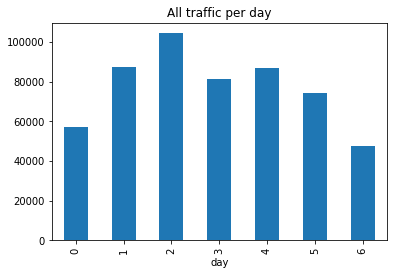

In [ ]:
# trips repartition by day
df.groupby(['day']).size().plot(kind='bar', title='All traffic per day')
plt.savefig('trafic_per_day_of_week.png')


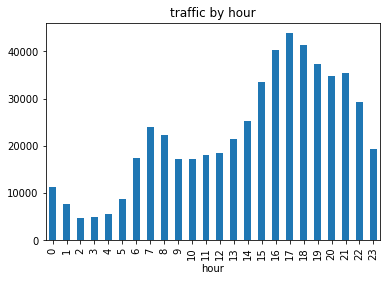

In [ ]:
# Look at the pick-ups repartition by hour
df.groupby(['hour']).size().plot(kind='bar', title='traffic by hour')
plt.savefig('traffic_by_hour.png')

In [ ]:
#Custom function to plot trafic  by day of week
def plot_hourly_traffic(dataframe, day) : 
  dataframe[dataframe.day == day].groupby(['hour']).size().plot(kind='bar')
  custom_title = 'trips on day ' + str(day) +' of week'
  plt.title(custom_title);

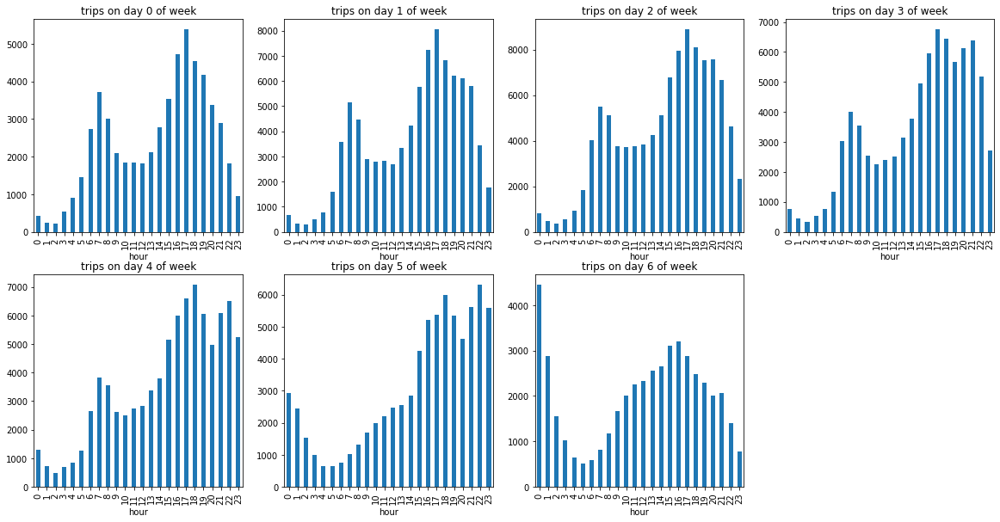

<Figure size 432x288 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20,10))

plt.subplot(241)
plot_hourly_traffic(df,0)


plt.subplot(242)
plot_hourly_traffic(df,1)

plt.subplot(243)
plot_hourly_traffic(df,2)

plt.subplot(244)
plot_hourly_traffic(df,3)

plt.subplot(245)
plot_hourly_traffic(df,4)

plt.subplot(246)
plot_hourly_traffic(df,5)

plt.subplot(247)
plot_hourly_traffic(df,6)

# plt.subplot(248)

plt.show()
plt.savefig('trafic_repartition_per_day_per_hour.png')


The previous graphs clearly show strong disparities in hourly traffic depending on the day of the week.
As a conclusion we cannot stratifly the dataset by hours only with a code like the below 


```
from sklearn.model_selection import train_test_split

Y = df.index #no use for Y

Subset_to_investigate, X_test, Y_train, Y_test = train_test_split( X, Y, test_size=0.2, random_state=42, stratify=X.hour)
```



# Stratify the dataset by day and hour

Flaws in data collection can sometimes cause sample data to have different proportions to known proportions. We are going on to explore how stratifying the dataset and resampling it to give it the same proportions to hours and days to improve performance 


In [ ]:
# Create a single feature that contains all of the data we want to stratify on as follows
def col_stratify(a,b):
  return 'day_' + str(a) + ', '+ 'hour_' + str(b)
  
df['stratify'] = df.apply(lambda x : col_stratify(x['day'], x['hour']), axis=1)

In [ ]:
df.sample()

,lat,lon,base,day,hour,stratify
218145,40.7089,-74.0166,B02598,2,22,"day_2, hour_22"


In [ ]:
#Estimate the percentage of trips by day and by hour
strat = df.groupby(['day','hour']).size().div(df.groupby(['day']).size()).mul(100).reset_index(name='nb_trips_perc')
strat.head(10)

,day,hour,nb_trips_perc
0,0,0,0.737794
1,0,1,0.431110
2,0,2,0.376783
3,0,3,0.949844
4,0,4,1.568469
5,0,5,2.528828
6,0,6,4.775507
7,0,7,6.520977
8,0,8,5.288984
9,0,9,3.652168


In [ ]:
strat['day'] = ['day_' + str(d) for d in strat.day]
strat['hour'] = ['hour_' + str(h) for h in strat.hour]
strat['day_hour'] = strat.day + ', ' + strat.hour
strat['nb_lignes'] = round(strat.nb_trips_perc * 50).astype('int') #50 is the coef for getting the number of lines

In [ ]:
strat.head(5)

,day,hour,nb_trips_perc,day_hour,nb_lignes
0,day_0,hour_0,0.737794,"day_0, hour_0",37
1,day_0,hour_1,0.431110,"day_0, hour_1",22
2,day_0,hour_2,0.376783,"day_0, hour_2",19
3,day_0,hour_3,0.949844,"day_0, hour_3",47
4,day_0,hour_4,1.568469,"day_0, hour_4",78


In [ ]:
criteria_nblines = strat[['day_hour', 'nb_lignes']].values

stratified_dataframe = pd.DataFrame()

# We create a stratified dataframe which complies with the number of days and hours of the original dataset
for key, value in enumerate(criteria_nblines):
  temp =  df[df.stratify == value[0]].sample(value[1], random_state=42)
  stratified_dataframe = pd.concat([ temp, stratified_dataframe], axis=0)
stratified_dataframe

,lat,lon,base,day,hour,stratify
427689,40.6482,-74.0000,B02682,6,23,"day_6, hour_23"
427680,40.7626,-73.9772,B02682,6,23,"day_6, hour_23"
190939,40.7308,-74.0009,B02598,6,23,"day_6, hour_23"
241802,40.7572,-73.9903,B02617,6,23,"day_6, hour_23"
140452,40.7637,-73.9638,B02598,6,23,"day_6, hour_23"
...,...,...,...,...,...,...
288389,40.7600,-73.9942,B02617,0,0,"day_0, hour_0"
266330,40.6629,-73.9883,B02617,0,0,"day_0, hour_0"
474417,40.7180,-73.9594,B02682,0,0,"day_0, hour_0"
266319,40.7388,-74.0081,B02617,0,0,"day_0, hour_0"


In [ ]:
stratified_dataframe.to_csv('stratified_df.csv')

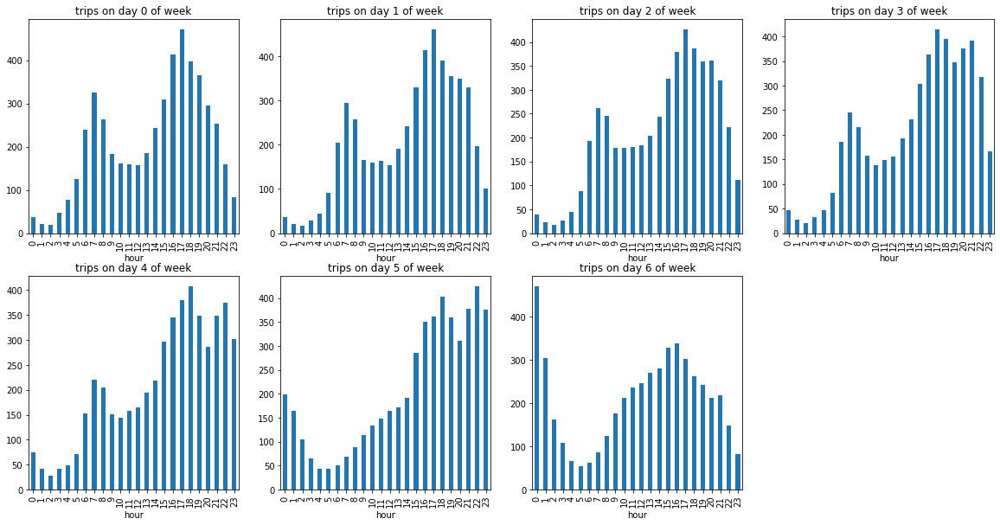

In [ ]:
# We plot the distribution of trips per day and per hour to check our distributions
import matplotlib.pyplot as plt
plt.figure(figsize=(20,10))

plt.subplot(241)
plot_hourly_traffic(stratified_dataframe,0)


plt.subplot(242)
plot_hourly_traffic(stratified_dataframe,1)

plt.subplot(243)
plot_hourly_traffic(stratified_dataframe,2)

plt.subplot(244)
plot_hourly_traffic(stratified_dataframe,3)

plt.subplot(245)
plot_hourly_traffic(stratified_dataframe,4)

plt.subplot(246)
plot_hourly_traffic(stratified_dataframe,5)

plt.subplot(247)
plot_hourly_traffic(stratified_dataframe,6)



plt.show()

Conclusion: we have successfully stratified our data

# In quest of the optimal number of clusters

In [ ]:
# Empirical Method:-
# A simple empirical method of finding number of clusters is Square root of N/2 where N is total number of data points, so that each cluster contains square root of 2 * 
# This is not necessarily the best approach. 
# One can say that in one of the most populated cities in the world, with many skyscrapers, it is quite possible that a large number of clusters is consistent with reality. 

In [ ]:
stratified_dataframe = pd.read_csv('/content/drive/MyDrive/09_11_uber/stratified_df.csv').drop(columns=['Unnamed: 0','base','day', 'hour', 'stratify'])

In [ ]:
X = stratified_dataframe.copy()

In [ ]:
print('According to the empirical method,', round(np.sqrt(X.shape[0]/2)), ' clusters seem  a little bit too big for analysis.')


According to the empirical method, 132  clusters seem  a little bit too big for analysis.


In [ ]:
# Import Standard Scaler
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
# StandardScaler will substract mean and divide by standard deviation to each observation
sc = StandardScaler()

# Apply StandardScaler to X
X_norm = sc.fit_transform(X)





---


**Ideal number of clusters with elbow method**

---



Check if data points within a cluster are close with their centroids.

**Inertia** is calculated by measuring the distance between each data point and its centroid, squaring this distance, and summing these squares across one cluster.

A good model is one with low inertia AND a low number of clusters (K).

To find the optimal K for a dataset, we find the point where the decrease in inertia begins to slow.

In [ ]:
# Let's create a loop that will collect the Within-sum-of-square (wcss) for each value K 
# Let's use .inertia_ parameter to get the within sum of square value for each value K 
from sklearn.cluster import KMeans
wcss =  []
k = []
for i in range (1,20): 
    kmeans = KMeans(n_clusters= i, init = "k-means++", random_state = 0)
    kmeans.fit(X_norm )
    wcss.append(kmeans.inertia_)
    k.append(i)
    print("WCSS for K={} --> {}".format(i, wcss[-1]))

WCSS for K=1 --> 69992.0
WCSS for K=2 --> 42789.63632152846
WCSS for K=3 --> 29304.492812542154
WCSS for K=4 --> 19132.420720251695
WCSS for K=5 --> 15258.723198948415
WCSS for K=6 --> 12751.134286453034
WCSS for K=7 --> 10898.580356137003
WCSS for K=8 --> 9876.529261335432
WCSS for K=9 --> 8958.71365769255
WCSS for K=10 --> 8100.901953987117
WCSS for K=11 --> 7397.768294763478
WCSS for K=12 --> 6732.889351972996
WCSS for K=13 --> 6210.2979876011495
WCSS for K=14 --> 5704.004593704846
WCSS for K=15 --> 5386.6307650526305
WCSS for K=16 --> 4934.145823913903
WCSS for K=17 --> 4581.780453547757
WCSS for K=18 --> 4319.974251743948
WCSS for K=19 --> 4124.678369678597


In [ ]:
#Sum of within-cluster variance, WCSS, is calculated for clustering analyses done with different values of k. 
# WCSS is a cumulative measure how good the points are clustered in the analysis. 
# Plotting the k values and their corresponding sum of within-cluster variance helps in finding the number of clusters. 


# Create DataFrame
wcss_frame = pd.DataFrame(wcss)
k_frame = pd.Series(k)

# Create figure
fig= px.line(
    wcss_frame,
    x=k_frame,
    y=wcss_frame.iloc[:,-1]
)

# Create title and axis labels
fig.update_layout(
    yaxis_title="Inertia",
    xaxis_title="# Clusters",
    title="Inertia per cluster",
    autosize=False,
    width=500,
    height=500,)


HTML(fig.to_html())

In [ ]:
# Ccl : 4 to 8 clusters



---

**Ideal number of clusters using Silhouette method**

---



Silhouette figures out **how far are each cluster from each other** (and therefore how meaningful they are).


The Silhouette Coefficient is calculated using :



*  the **mean intra-cluster distance (a) **
*  the **mean nearest-cluster distance (b)** for each sample



The Silhouette coefficient for a sample is 

**(b - a) / max(a, b)**. 

To clarify, b is the distance between a sample and the nearest cluster that the sample is not a part of. 

Silhouette Coefficient is only defined if number of labels is 2 <= n_labels <= n_samples - 1

In [ ]:
# Import silhouette score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Computer mean silhouette score
sil = []
k = []

## Careful, you need to start at i=2 as silhouette score cannot accept less than 2 labels 
for i in range (2,20): 
    kmeans = KMeans(n_clusters= i, init = "k-means++",random_state = 0)
    kmeans.fit(X_norm)
    sil.append(silhouette_score(X_norm, kmeans.predict(X_norm)))
    k.append(i)
    print("Silhouette score for K={} is {}".format(i, sil[-1]))

Silhouette score for K=2 is 0.411860955642942
Silhouette score for K=3 is 0.4355206982781544
Silhouette score for K=4 is 0.4742002752450998
Silhouette score for K=5 is 0.42066534002083783
Silhouette score for K=6 is 0.43211795814958776
Silhouette score for K=7 is 0.3796164703798673
Silhouette score for K=8 is 0.3749305447079178
Silhouette score for K=9 is 0.3826367762373446
Silhouette score for K=10 is 0.38337844681473426
Silhouette score for K=11 is 0.39345084160749383
Silhouette score for K=12 is 0.39266983511538933
Silhouette score for K=13 is 0.39409193660670266
Silhouette score for K=14 is 0.3980565240427391
Silhouette score for K=15 is 0.38634770432913446
Silhouette score for K=16 is 0.4069621442368967
Silhouette score for K=17 is 0.40874239749597885
Silhouette score for K=18 is 0.397179124369778
Silhouette score for K=19 is 0.3925982083247602


In [ ]:
# Create a data frame 

cluster_scores=pd.DataFrame(sil, index=k, columns = ['silhouette_score'])

# Create figure
fig = px.line(data_frame=cluster_scores,  
            x = cluster_scores.index,
            y = cluster_scores.silhouette_score
            )

# Add title and axis labels
fig.update_layout(
    yaxis_title="Silhouette Score",
    xaxis_title="# Clusters",
    title="Silhouette Score per cluster", 
    width=500,
    height=500,
)


# Render
HTML(fig.to_html())

In [ ]:

# a range from 4 to 7 seem to be correct estimations of number of clusters



---



**Optimal number of clusters with clusteval python package**

---



clusteval is Python package for unsupervised cluster evaluation. The methods can be used to evaluate optimal number of clusters 
cf https://github.com/erdogant/clusteval

In [ ]:
!pip install clusteval

In [ ]:
from clusteval import clusteval

In [ ]:
from clusteval import clusteval
# Determine the optimal number of clusters

ce = clusteval(method='silhouette')
ce.fit(X_norm)


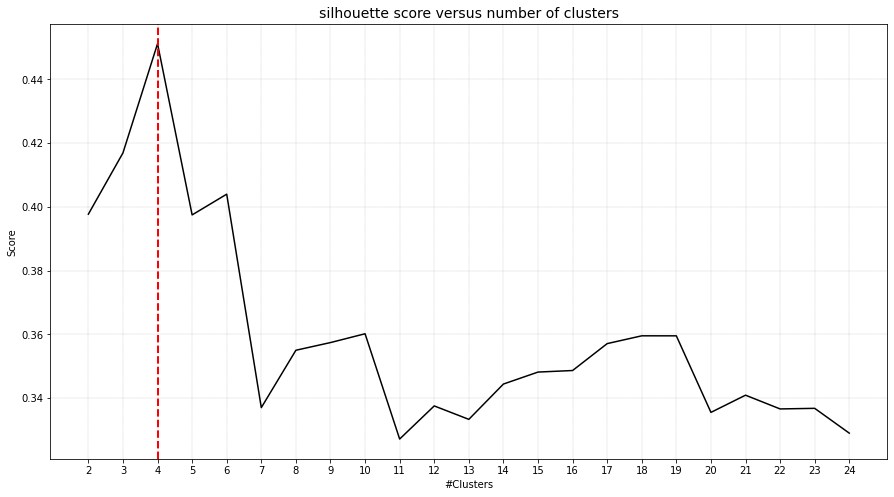

(<Figure size 1080x576 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f853bd8a7d0>)

In [ ]:
ce.plot()


***Conclusion : ***

We will take 4 clusters as stated in the previous steps

# Kmeans clustering

K-Means method is a partitioning technique that separates observations into K groups, where each observation is considered to belong to the group where the **mean is the closest according to a given distance**. Clusters have to be convex and isotropic. It simply means that clusters should have a relatively rounded shape and data points shouldn't be too far from each other.

As KK is iniatilized at random, the algorithm can converge to a local minimum. In sklearn, the way to alleviate this problem is to initialize KK using k-means++ which makes sure that each cluster centers are far from each other. 

In [ ]:
os.chdir('/content/drive/MyDrive/09_11_uber/new_data_viz')

**Code factorization for better understanding**

In [ ]:
#Custom function to plot clusters
import plotly.graph_objects as go
from sklearn.cluster import KMeans

def kmeans_plot(X, nb_cluster, bars):
  # Instanciate KMeans with current "ideal number of clusters" and initialisation with k-means++
  # We use k-means++ as it alleviate the problem of local minimum convergence
  kmeans = KMeans(n_clusters=nb_cluster , init="k-means++")
  kmeans.fit(X)

  #  The KMeans algorithm theoretically requires that the data be normalized. 
  #  In this case, the latitude and longitude are of the same order of size. 
  #  So, there is no point in normalizing the data. 
  #  Moreover, it would make plotting the points more problematic, since the inverse transformation would have to be applied to them before displaying them 


  # Cluster centers coordinates
  kmeans.cluster_centers_
  X['cluster'] = kmeans.predict(X)
  
  mapbox_access_token = open('/content/drive/MyDrive/09_11_uber/mapbox_token').read()
  fig = go.Figure()

  #Data points
  fig.add_trace(go.Scattermapbox( 
      lat=X.lat, 
      lon=X.lon, 
      mode='markers',
      marker=go.scattermapbox.Marker(
              color=X.cluster,
              opacity = 0.4),
  ))


  #Centroids
  fig.add_trace(go.Scattermapbox( 
      mode='markers', 
      lat=[v[0] for k,v in enumerate(kmeans.cluster_centers_)], 
      lon=[v[1] for k,v in enumerate(kmeans.cluster_centers_)], 
      text= [k for k,v in enumerate(kmeans.cluster_centers_)], 
      marker=dict(  
                  size=5, 
                  symbol = 'car'
                  ), 
      ))

  ####Condition : we can choose to display or not major points of interests in NY : incredible rooftops, lounge bars...
  if bars == True:
    title_ = "Uber trafic clustering with " + str(nb_cluster) + " clusters. Red circles = venues, cars = centroids"
  
    fig.add_trace(go.Scattermapbox( 
        mode='markers', 
        lat=[40.70372, 40.73346,40.77370,40.77207,40.69319,40.718340, 40.67536,40.76020] ,
        lon=[-74.01105,-73.98596, -73.98298,-73.95789,-73.97890, -73.96306,-73.94964,-73.83559],
        text= [ "Ampia Rooftop" ,"The Ready Rooftop Bar","The Empire Rooftop","Lexington Bar and Books","Kimoto Rooftop",
            
              "Elite Williamsburg","Sweet Brooklyn Bar","A+ Roof Bar"], 
        hoverinfo='text',
        marker=go.scattermapbox.Marker(
                size=17,
                color='rgb(255, 0, 0)',
                opacity=0.7), 
        ))

    fig.add_trace(go.Scattermapbox( 
        mode='markers', 
          lat=[40.70372, 40.73346,40.77370,40.77207,40.69319,40.718340, 40.67536,40.76020] ,
          lon=[-74.01105,-73.98596, -73.98298,-73.95789,-73.97890, -73.96306,-73.94964,-73.83559],
        
        marker=go.scattermapbox.Marker(
                size=8,
                color='rgb(242, 177, 172)',
                opacity=0.7), 
        ))



  title_ = "Uber trafic clustering with " + str(nb_cluster) + " clusters. Centroids are marked by cars"
  img_title = 'kmeans_' + str(nb_cluster) + '_clusters.png'
  fig.update_layout(
      autosize=False,
      width=800,
      height=800,
      mapbox=dict(accesstoken=mapbox_access_token),
      title= dict(text =title_)
      )
  fig.update_layout(
      hovermode='closest',
      showlegend=False,
      mapbox=dict(
          accesstoken=mapbox_access_token,
          bearing=0,
          center=go.layout.mapbox.Center(
              lat= np.mean([v[0] for k,v in enumerate(kmeans.cluster_centers_)]),
              lon=np.mean([v[1] for k,v in enumerate(kmeans.cluster_centers_)])
          ),
          pitch=0,
          zoom=10.4, 
          style='light')
  )
  #According to plotly doc : 
  # https://community.plotly.com/t/scattergl-plots-disappearing/38983/3 
  # "There’s a limit of 8 scattergl plots per page, due a limited number of WebGL contexts made available to the page by the browser."
  # So we save each plot for further analysis
  fig.write_image(img_title)
  return fig.show(renderer='colab')




**Trial with "ideal" empirical number of clusters (132)**

In [ ]:
X = stratified_dataframe.copy()
nb_cluster=132
kmeans_plot(X, nb_cluster, bars=False)

In [ ]:
# Image saved here : 
# https://drive.google.com/file/d/1-1eUsPOoaSNYobF1xf7vGjidtrwvMU9I/view?usp=sharing

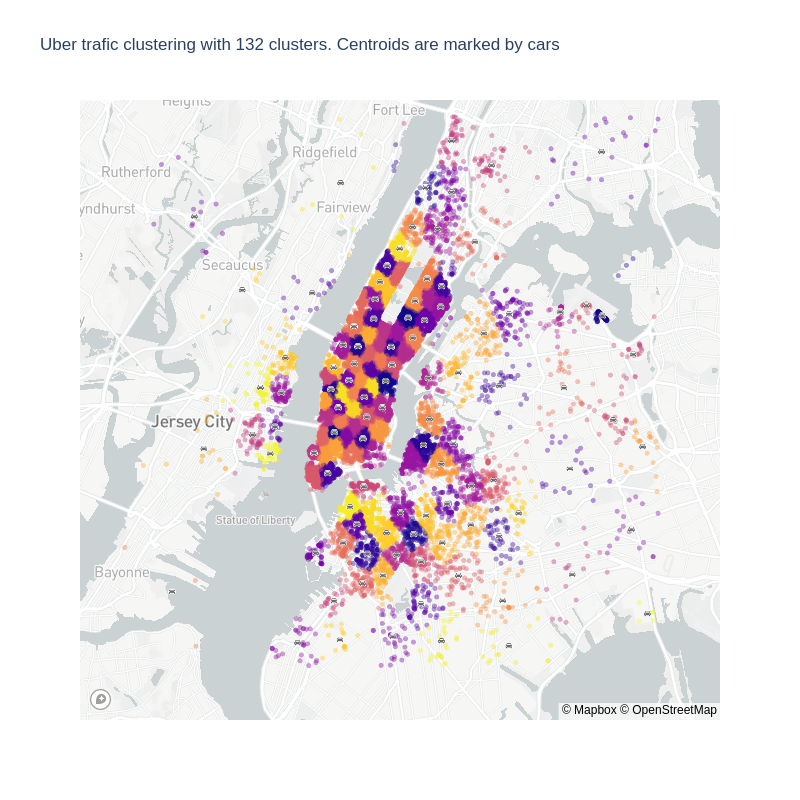

In [ ]:
Image("/content/drive/MyDrive/09_11_uber/new_data_viz/kmeans_132_clusters.png")

This empirical option has the interest of showing that there are hot zones by groups of blocks. 

It is also possible to define very precise zones consistent with the density of the city and the habits of the drivers (i.e., turn around blocks where there is always someone working or wanting to go out). 

Nevertheless, for the continuation, we will rather adopt a "high level" approach to better identify large homogeneous regions where drivers work.



**Trial with approach k= 4**

In [ ]:
X = stratified_dataframe.copy()
nb_cluster=4
kmeans_plot(X, nb_cluster, bars= True)

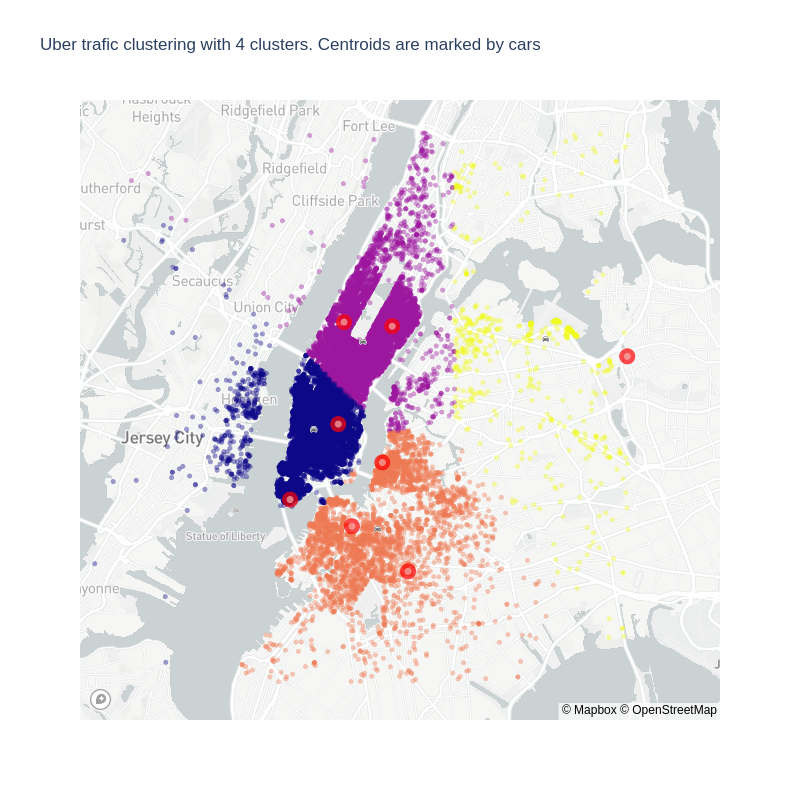

In [ ]:
Image('/content/drive/MyDrive/09_11_uber/new_data_viz/kmeans_4_clusters.png')
#Image saved here 
# https://drive.google.com/file/d/1-88vkyb0xzdE4SybGZSU-IzA8cswsu_7/view?usp=sharing

**Trial with k = 10**

In [ ]:
X = stratified_dataframe.copy()
nb_cluster=10
kmeans_plot(X, nb_cluster, bars= True)

In [ ]:
# image available here
# https://drive.google.com/file/d/1-8dXceryW1wkK75ajM9MyDNwgMy4H0CG/view?usp=sharing

Let's now display the evolution of the clusters according to the time.  We restore the day and time from our stratified minified dataframe

In [ ]:
XX = stratified_dataframe.drop(columns=['lat', 'lon', 'base','stratify'])
X1 = XX.merge(X,left_on=XX.index, right_on=X.index, how='left').drop(columns='key_0')
X1.sample(5)

,day,hour,lat,lon,cluster,cluster_color
24816,2,5,40.6994,-73.9316,2,#00CC96
6870,5,18,40.7366,-73.9909,1,#EF553B
34197,0,7,40.7657,-73.9628,0,#636EFA
11005,4,21,40.7692,-73.9571,0,#636EFA
15567,3,21,40.7614,-73.9817,0,#636EFA


**Evolution of trafic according to day of week**

In [ ]:

fig = px.scatter_mapbox(
        X1.sort_values(by='day', ascending=True),
        lat="lat", 
        lon="lon",
        color='cluster_color',
        mapbox_style="carto-positron",
        zoom=10.4,
        animation_frame='day',
)

fig.update_layout(
    autosize=False,
    width=600,
    height=600,
    showlegend=False,
    title= 'Trafic by day of week'
    )
HTML(fig.to_html())

In [ ]:
fig.write_html("kmeans_trafic_by_day")

In [ ]:
HTML("/content/drive/MyDrive/09_11_uber/data_viz/kmeans_trafic_by_day")
# https://drive.google.com/file/d/11RLsvc8nP80AmLOuIsRrG5LsbSWm0Cu5/view?usp=sharing

**Evolution of trafic by hour**

In [ ]:

fig = px.scatter_mapbox(
        X1.sort_values(by='hour', ascending=True),
        lat="lat", 
        lon="lon",
        color='cluster_color',
        mapbox_style="carto-positron",
        zoom=10.4,
        animation_frame='hour',
)

fig.update_layout(
    autosize=False,
    width=600,
    height=600,
    showlegend=False,
    title= 'Trafic by hour'
    )
HTML(fig.to_html())

In [ ]:
fig.write_html("kmeans_trafic_by_hour")

In [ ]:
HTML("/content/drive/MyDrive/09_11_uber/data_viz/kmeans_trafic_by_hour")
# https://drive.google.com/file/d/11SIcL4xxHI5H5mELsV2_bhW_WT0PDpew/view?usp=sharing

# Clustering with DBSCAN

DBSCAN stands for Density-Based Spatial Clustering of Applications with Noise.

Contrary to K-Means, DBSCAN does not require to initialize a number of cluster in advance. Instead, it uses the concept of density to assign observations to a cluster.

In a given area, density is equal to the number of observations located in that area.

A **core point** is a point that has more than min_sample neighbors within a radius of size eps.

A **border points** as its name implies are observations at the edge of a cluster, which define its boundary. More precisely it is any point that has **less than min_sample neighbors within its neighborhood** of radius eps but has **at least one neighbor that is a core point**.

**Noise/outliers** which are simply the points that are neither Core points nor border points. Concretely they **have less than min_sample neighbors within their neighborhood** of radius eps and **none of their neighbors are core points**. You can also consider these observations as outliers.




---


Determination of the min_samples parameter



---


There is no automatic way to determine the MinPts value for DBSCAN. Ultimately, the MinPts value should be set using domain knowledge and familiarity with the data set. From some lectures, there are a few rules of thumb for selecting the MinPts value:

The larger the data set, the larger the value of MinPts 'may' be.

If the data set is noisier, one may choose a larger value of MinPts.

Generally, MinPts should be greater than or equal to the dimensionality of the data set.

For 2-dimensional data, use DBSCAN’s default value of MinPts = 4 (Ester et al., 1996).

If your data has more than 2 dimensions, choose MinPts = 2*dim, where dim= the dimensions of your data set (Sander et al., 1998).



---



Determination of the epsilon parameter


---



In [ ]:
X = stratified_dataframe.drop(columns=['base','stratify', 'day', 'hour'])
#.drop(columns=['base', 'stratify', 'day', 'hour'])

In [ ]:
X.sample(5)

,lat,lon
203984,40.7270,-73.9915
64463,40.6722,-74.0107
428408,40.7829,-73.9757
471238,40.7235,-74.0096
124606,40.7110,-74.0160


In [ ]:
# Scikit-Learn provides a NearestNeighbors class 
# which allows to determine the nearest neighbors 
# of each observation as well as the distances.
from sklearn.neighbors import NearestNeighbors
import plotly.express as px

neighbors = 4

nbrs = NearestNeighbors(n_neighbors=neighbors ).fit(X)
distances, indices = nbrs.kneighbors(X)
distance_desc = sorted(distances[:,neighbors-1], reverse=True)
fig = px.line(x=list(range(1,len(distance_desc )+1)),y= distance_desc )
fig.show(renderer='colab')

The article https://stats.stackexchange.com/questions/88872/a-routine-to-choose-eps-and-minpts-for-dbscan gives a method to determine the epsilon parameter

In [ ]:
!pip install kneed

In [ ]:
from kneed import KneeLocator
kneedle = KneeLocator(range(1,len(distance_desc)+1),  #x values
                      distance_desc, # y values
                      S=1.0, #parameter suggested from paper
                      curve="convex", #parameter from figure
                      direction="decreasing") #parameter from figure

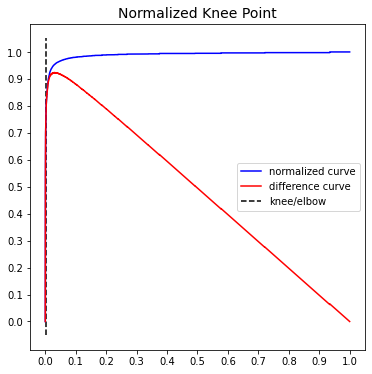

In [ ]:
kneedle.plot_knee_normalized()

In [ ]:
# the commands kneedle.elbow or kneedle.knee returns the index of the x array, and the kneedle.
# knee_y returns the optimum value for ϵ.
kneedle.knee_y

0.007872102641601594

In [ ]:
X = stratified_dataframe.drop(columns=['base', 'stratify', 'day', 'hour'])
X.sample(2)

,lat,lon
85823,40.7244,-74.0057
491604,40.7746,-73.9621


In [ ]:
# we test DBSCAN model with these parameters
from sklearn.cluster import DBSCAN


db = DBSCAN( eps=kneedle.knee_y,metric='euclidean',  min_samples=4, leaf_size=20)
X['cluster'] = db.fit_predict(X)


In [ ]:
X = stratified_dataframe.drop(columns=['base', 'stratify', 'day', 'hour'])
db = DBSCAN( eps=0.007872102641601594,metric='euclidean',  min_samples=4, leaf_size=20)
X['cluster'] = db.fit_predict(X)

plotting clusters
We can obviously find the centroids of clusters found from the DBSCAN after getting all the samples in a cluster and then calculating their mean.

In [ ]:
import plotly.graph_objects as go

mapbox_access_token = open('/content/drive/MyDrive/09_11_uber/mapbox_token').read()
fig = go.Figure()

#Data points
fig.add_trace(go.Scattermapbox( 
    lat=X.lat, 
    lon=X.lon, 
    text = X.cluster,
    mode='markers',

    marker=go.scattermapbox.Marker(
            size=8,
            color=X.cluster,
            colorbar=dict(
            title="cluster"
        ),
        colorscale="Teal"
        ),
))

#DBSCAN centroids
fig.add_trace(go.Scattermapbox( 
      mode='markers', 
      lat = X.groupby(['cluster'])['lat', 'lon'].mean()['lat'].tolist(), 
      lon=X.groupby(['cluster'])['lat', 'lon'].mean()['lon'].tolist(), 
      text= X.groupby(['cluster'])['lat', 'lon'].mean().reset_index()[['cluster']].values ,
      marker=go.scattermapbox.Marker(
            size=17,
            color='rgb(255, 0, 0)',
            opacity=0.7), 
     ))


fig.add_trace(go.Scattermapbox( 
      mode='markers', 
      lat =X.groupby(['cluster'])['lat', 'lon'].mean()['lat'].tolist(), 
      lon=X.groupby(['cluster'])['lat', 'lon'].mean()['lon'].tolist(), 
      text= X.groupby(['cluster'])['lat', 'lon'].mean().index ,
     hoverinfo='none',
     marker=go.scattermapbox.Marker(
            size=8,
            color='rgb(242, 177, 172)',
            opacity=0.7),
     ))

fig.update_layout(
    autosize=False,
    width=600,
    height=600,
    mapbox=dict(accesstoken=mapbox_access_token),
    title= dict(text ="Uber trafic clustering with DBSCAN.")
    )
fig.update_layout(
    # hovermode='closest',
    showlegend=False,
    mapbox=dict(
        accesstoken=mapbox_access_token,
        bearing=0,
        center=go.layout.mapbox.Center(
            lat= 40.75,
            lon=-73.95
        ),
        pitch=0,
        zoom=10, 
        style='light')
)


fig.show(renderer='colab')

In [ ]:
os.chdir('/content/drive/MyDrive/09_11_uber/data_viz/dbscan')
fig.write_html("dbscan_clustering")

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/dbscan_clustering')
# https://drive.google.com/file/d/1-bw0_1HP-DUMwfL2jel1A5fDZq6xKmV7/view?usp=sharing

In [ ]:
# What are the clusters size ? 
X.cluster.value_counts().to_frame().head(10)

,cluster
0,34449
2,365
-1,56
10,15
5,14
3,10
14,9
17,9
8,9
6,9


In [ ]:
# let's display the major ones
big_cluster = X.cluster.value_counts().to_frame().head(5).reset_index()['index'].tolist()

In [ ]:
import plotly.graph_objects as go

mapbox_access_token = open('/content/drive/MyDrive/09_11_uber/mapbox_token').read()
fig = go.Figure()

#Data points
fig.add_trace(go.Scattermapbox( 
    lat=X[X.cluster.isin(big_cluster) ].lat, 
    lon=X[X.cluster.isin( big_cluster)].lon, 
    text = X.cluster,
    mode='markers',

    marker=go.scattermapbox.Marker(
            size=8,
            color=X.cluster,
            opacity = 0.8,
            colorbar=dict(
            title="cluster"
        ),
        colorscale="Teal"
        ),
))

#DBSCAN centroids
fig.add_trace(go.Scattermapbox( 
      mode='markers', 
      lat = X.groupby(['cluster'])['lat', 'lon'].mean()['lat'].tolist(), 
      lon=X.groupby(['cluster'])['lat', 'lon'].mean()['lon'].tolist(), 
      text= X.groupby(['cluster'])['lat', 'lon'].mean().reset_index()[['cluster']].values ,
      marker=go.scattermapbox.Marker(
            size=17,
            color='rgb(255, 0, 0)',
            opacity=0.7), 
     ))


fig.add_trace(go.Scattermapbox( 
      mode='markers', 
      lat =X.groupby(['cluster'])['lat', 'lon'].mean()['lat'].tolist(), 
      lon=X.groupby(['cluster'])['lat', 'lon'].mean()['lon'].tolist(), 
      text= X.groupby(['cluster'])['lat', 'lon'].mean().index ,
    #  hoverinfo='none',
     marker=go.scattermapbox.Marker(
            size=8,
            color='rgb(242, 177, 172)',
            opacity=0.7),
     ))


fig.update_layout(
    autosize=False,
    width=600,
    height=600,
    mapbox=dict(accesstoken=mapbox_access_token),
    title= dict(text ="main clusters with DBSCAN")
    )
fig.update_layout(
    # hovermode='closest',
    showlegend=False,
    mapbox=dict(
        accesstoken=mapbox_access_token,
        bearing=0,
        center=go.layout.mapbox.Center(
            lat= 40.75,
            lon=-73.95
        ),
        pitch=0,
        zoom=11, 
        style='light')
)


fig.show(renderer='colab')

In [ ]:
fig.write_html('dbscan_main_clusters')


In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/dbscan_main_clusters')
# https://drive.google.com/file/d/11lSHGIf3jWDviDtcpG8OcGMupbzbeuoz/view?usp=sharing

With this approach, the problem is that we find  one "very" large cluster, which does not segment properly the dataset.What if we test new parameters ? Business insights can sometimes help sometimes not (...)

# Trials to perform better DBSCAN Modeling

In [ ]:
from sklearn.cluster import DBSCAN
best_param = kneedle.knee_y

In [ ]:
#Function to plot clusters
def plot_image(X, param):
  import plotly.graph_objects as go
  mapbox_access_token = open('/content/drive/MyDrive/09_11_uber/mapbox_token').read()
  fig = go.Figure()

  #Data points
  fig.add_trace(go.Scattermapbox( 
      lat=X.lat, 
      lon=X.lon, 
      text = X.cluster,
      mode='markers',
      marker=go.scattermapbox.Marker(
              # size=8,
              color=X.cluster,
              colorbar=dict(
              title="cluster",
          ),
          colorscale="Teal"
          ),
  ))

#DBSCAN centroids
  fig.add_trace(go.Scattermapbox( 
        mode='markers', 
        lat = X.groupby(['cluster'])['lat', 'lon'].mean()['lat'].tolist(), 
        lon=X.groupby(['cluster'])['lat', 'lon'].mean()['lon'].tolist(), 
        text= X.groupby(['cluster'])['lat', 'lon'].mean().reset_index()[['cluster']].values ,
        marker=go.scattermapbox.Marker(
              size=17,
              color='rgb(255, 0, 0)',
              opacity=0.7), 
      ))


  fig.add_trace(go.Scattermapbox( 
        mode='markers', 
        lat =X.groupby(['cluster'])['lat', 'lon'].mean()['lat'].tolist(), 
        lon=X.groupby(['cluster'])['lat', 'lon'].mean()['lon'].tolist(), 
        text= X.groupby(['cluster'])['lat', 'lon'].mean().index ,
      hoverinfo='none',
      marker=go.scattermapbox.Marker(
              size=8,
              color='rgb(242, 177, 172)',
              opacity=0.7),
      ))

  fig.update_layout(
      autosize=False,
      width=600,
      height=600,
      mapbox=dict(accesstoken=mapbox_access_token),
      title= dict(text ="clustering with DBSCAN (eps value : {}".format(param))
      )
  fig.update_layout(
      hovermode='closest',
      showlegend=False,
      mapbox=dict(
          accesstoken=mapbox_access_token,
          bearing=0,
          center=go.layout.mapbox.Center(
              lat= 40.75,
              lon=-73.95
          ),
          pitch=0,
          zoom=10.4, 
          style='light')
  )


  return fig

**trial with leaf_size=100 & eps = best_param**

In [ ]:
# trial with leaf_size=100
X = stratified_dataframe.drop(columns=['base', 'stratify', 'day', 'hour'])
db = DBSCAN( eps=best_param ,metric='euclidean',  min_samples=4, leaf_size=100)
X['cluster'] = db.fit_predict(X)
fig_0 = plot_image(X, 'best_param, min_leaf 100')
fig_0.write_html('dbscan_best_param_min_leaf_100')
HTML('dbscan_best_param_min_leaf_100')


In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/dbscan_best_param_min_leaf_100')
# https://drive.google.com/file/d/11t6yJqIcNRr8aqFZzvFEc7Nx3C0eIc4G/view?usp=sharing

In [ ]:
X.cluster.value_counts(normalize = True).to_frame().describe().T

,count,mean,std,min,25%,50%,75%,max
cluster,19.0,0.052632,0.225643,0.000114,0.000157,0.000257,0.000343,0.98437


In [ ]:
# conclusion : not much change and some new extra clusters


**Trial with best_param x 0.5**

In [ ]:
X = stratified_dataframe.drop(columns=['base', 'stratify', 'day', 'hour'])
db = DBSCAN( eps=best_param*0.5 ,metric='euclidean',  min_samples=4, )
X['cluster'] = db.fit_predict(X)
fig_1 = plot_image(X, 'best_param x 0.5')
fig_1.write_html('dbscan_best_param_x_0.5')



In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/dbscan_best_param_x_0.5')
# https://drive.google.com/file/d/122usOTHyPCtK8BCst8Plz-XFn5pVOpAR/view?usp=sharing

In [ ]:
X.cluster.value_counts(normalize = True).to_frame().describe().T

,count,mean,std,min,25%,50%,75%,max
cluster,36.0,0.027778,0.157884,0.000086,0.000136,0.000257,0.000986,0.948623


**Trial with kneedle.knee_y/20**

In [ ]:

db = DBSCAN( eps=best_param/20 ,metric='euclidean',  min_samples=4, )
X['cluster'] = db.fit_predict(X)
fig_2 = plot_image(X, 'best_param / 20')
fig_2.write_html('db_scan_param_div_20')
HTML('db_scan_param_div_20')


In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/db_scan_param_div_20')
# https://drive.google.com/file/d/127XYP0D_-vPePYtrDtGLFEitehaB0ASe/view?usp=sharing

In [ ]:
# This view is not clear but shows new clusters in the center of the city (centroids are shown in red)

In [ ]:
X.cluster.value_counts(normalize = True).to_frame().describe().T

,count,mean,std,min,25%,50%,75%,max
cluster,961.0,0.001041,0.014724,0.000086,0.000143,0.0002,0.000343,0.415819


In [ ]:
#Too many small clusters ... Let's plot the clusters without centroids
def plot_image_without_centroid(X, param):
  import plotly.graph_objects as go
  mapbox_access_token = open('/content/drive/MyDrive/09_11_uber/mapbox_token').read()
  fig = go.Figure()

  #Data points
  fig.add_trace(go.Scattermapbox( 
      lat=X.lat, 
      lon=X.lon, 
      text = X.cluster,
      mode='markers',
      marker=go.scattermapbox.Marker(
              # size=8,
              color=X.cluster,
              colorbar=dict(
              title="cluster",
          ),
          colorscale="Teal"
          ),
  ))

  fig.update_layout(
      autosize=False,
      width=600,
      height=600,
      mapbox=dict(accesstoken=mapbox_access_token),
      title= dict(text ="Uber trafic clustering with DBSCAN (eps value : {}".format(param))
      )
  fig.update_layout(
      hovermode='closest',
      showlegend=False,
      mapbox=dict(
          accesstoken=mapbox_access_token,
          bearing=0,
          center=go.layout.mapbox.Center(
              lat= 40.75,
              lon=-73.95
          ),
          pitch=0,
          zoom=10.4, 
          style='light')
  )
  return fig

In [ ]:
fig_3 = plot_image_without_centroid(X, 'best_param/20')
fig_3.write_html('best_param_div_20_without_c')
HTML('best_param_div_20_without_c')

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/best_param_div_20_without_c')
# https://drive.google.com/file/d/127gR8Xy1PqxlRY_btpsrMHhQZCx6UsC9/view?usp=sharing

In [ ]:
# There is indeed a greater granularity when the eps parameter is decreased


Conclusion : 
Despite all these tests (and not all of them are are not included in this notebook), the results are still not optimal.

# Last but not least : DBSCAN with day and hours features

In [ ]:
X = stratified_dataframe.drop(columns=['base', 'stratify'])
neighbors = 4

nbrs = NearestNeighbors(n_neighbors=neighbors ).fit(X)
distances, indices = nbrs.kneighbors(X)
distance_desc = sorted(distances[:,neighbors-1], reverse=True)

from kneed import KneeLocator
kneedle = KneeLocator(range(1,len(distance_desc)+1),  #x values
                      distance_desc, # y values
                      S=1.0, #parameter suggested from paper
                      curve="convex", #parameter from figure
                      direction="decreasing") #parameter from figure

param  = kneedle.knee_y
print(param)
db = DBSCAN( eps=param,metric='euclidean',  min_samples=8)
X['cluster'] = db.fit_predict(X)

0.04538160420257674


In [ ]:
X.cluster.value_counts().to_frame().describe().T

,count,mean,std,min,25%,50%,75%,max
cluster,183.0,191.234973,129.61212,8.0,72.5,182.0,302.5,469.0


In [ ]:
fig_4 = plot_image(X, ' 0.0453' )
fig_4.write_html('clustering_with_days_and_hours')


In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/clustering_with_days_and_hours')
#Please see https://drive.google.com/file/d/12DZrBehsxDRQOzytLM2Rh-De0Lc3kJcb/view?usp=sharing

**Traffic per day**

In [ ]:
#Please seefig = px.scatter_mapbox(
        X.sort_values(by='day', ascending=True),
        lat="lat", 
        lon="lon",
        color='cluster',
        mapbox_style="carto-positron",
        zoom=10.4,
        animation_frame='day',
)

fig.update_layout(
    autosize=False,
    width=600,
    height=600,
    showlegend=False,
    title= 'Trafic by hour'
    )
fig.show(render='colab')

In [ ]:
fig.write_html("dbscan_trafic_per_day")


In [ ]:
HTML(('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/dbscan_trafic_per_day'))
#Please see https://drive.google.com/file/d/12WR1-qx1wlVPT7velAvTik1nsAoh4gw0/view?usp=sharing

# Let's systematize this approach to display traffic for each day

In [ ]:
def day_clustering(dday):
  X = stratified_dataframe.drop(columns=['base', 'stratify'])  
  XX = X[X.day == dday]
  XX['hour'] = XX['hour'].astype(int)
  XX = XX.sort_values(by='hour', ascending=True)
  db = DBSCAN( eps=param,metric='euclidean',  min_samples=8)
  XX['cluster'] = db.fit_predict(XX)

  fig = px.scatter_mapbox(
       XX,
        lat=XX.lat,
        lon =XX.lon,
        color=XX.cluster,
        mapbox_style="carto-positron",
        zoom=10.4,
        animation_frame=XX.hour,
)

  fig.update_layout(
      autosize=False,
      width=600,
      height=600,
      showlegend=False,
      title= 'Traffic by hour on day {} '.format(dday)
      )
  img_name = 'Traffic by hour on day ' +str(dday)
  fig.write_html(img_name)
  return HTML(img_name)

In [ ]:
for x in range(7):
  day_clustering(x)

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/Traffic by hour on day 0')
# https://drive.google.com/file/d/12wvEqAB6kvNtxnyujnx0IYfSUWV7KdI8/view?usp=sharing

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/Traffic by hour on day 1')
# https://drive.google.com/file/d/13BYYImlTHU72ApeIOSkYPdzqjWdxnrz1/view?usp=sharing

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/Traffic by hour on day 2')
# https://drive.google.com/file/d/139mWN-WbFu5wd-J6sAcIcv6gFz2CyzY7/view?usp=sharing

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/Traffic by hour on day 3')
# https://drive.google.com/file/d/135U_JkW9ABw0XEZFB6kq7PKGaXp8i2sF/view?usp=sharing


In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/Traffic by hour on day 4')
# https://drive.google.com/file/d/13Gmd8MSTs8QZelgYBIrqe821DMq8EJ7F/view?usp=sharing

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/Traffic by hour on day 5')
# https://drive.google.com/file/d/13KUwH5GfGnF5XIoCTC_c1SVoMe76H8WS/view?usp=sharing

In [ ]:
HTML('/content/drive/MyDrive/09_11_uber/data_viz/dbscan/Traffic by hour on day 6')
# https://drive.google.com/file/d/13JPcVELpa4UDrFzGZnZQ3rymPdaX1xfI/view?usp=sharing

# Conclusion

---

All this indicates where the ubers are. But it in no way gives us the location of the customers who use their service.

Are ubers there when and where customers need them? This would certainly need to be verified more accurately.
